# 14 — C-NMC classification paper results

**Purpose:** Assemble paper tables and prose from actual experiment files only.

**Required inputs:** Outputs from notebooks 09–13 when available.

**Saved outputs:** outputs/classifier/paper_results/classifier_* files.

## 1. Load central configuration

Set `cnmc_root` once in ignored `config.local.yaml`. Source images are never moved or changed.

In [1]:
from pathlib import Path
import os, sys
search = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("LEUKEMIA_YOLO_ROOT"):
    search.insert(0, Path(os.environ["LEUKEMIA_YOLO_ROOT"]))
for candidate in search:
    if (candidate / "config.example.yaml").is_file() and (candidate / "src" / "classifier_config.py").is_file():
        sys.path.insert(0, str(candidate)); break
from src.classifier_config import classifier_config, classifier_output
cfg = classifier_config()
out = classifier_output(cfg)
print("Project:", cfg["root"])
print("Config:", cfg["config_path"])
print("C-NMC source:", cfg["cnmc_root"])

Project: D:\CellCancer\leukemia-yolo
Config: D:\CellCancer\leukemia-yolo\config.local.yaml
C-NMC source: D:\Datasets\C-NMC_Leukemia


## 2. Assemble evidence

Missing experiments remain explicitly Not available.

In [2]:
from src.classifier_reporting import assemble_classifier_report
import pandas as pd
report = assemble_classifier_report(cfg)
display(pd.DataFrame([{"item": key, "value": str(value)} for key, value in report.items()]))

,item,value
0,source,C-NMC-2019 (TCIA); Kaggle avk256/cnmc-leukemia
1,source_images,10661
2,source_class_counts,"{'ALL': 7272, 'HEM': 3389}"
3,source_subjects,73
4,split_protocol,fold_2 fixed test; fold_0+fold_1 subject-strat...
5,split_counts,"{'train': {'images': 4667, 'subjects': 30, 'no..."
6,excluded_candidate_images,1256
7,excluded_candidate_subjects,"['ALL:20', 'ALL:51', 'HEM:H10', 'HEM:H6']"
8,split_exclusion_policy,Keep all fold_2 test rows; exclude whole candi...
9,architecture,Torchvision EfficientNet-B3


## 3. Review figures and limitations

Validation and held-out test results have separate names and provenance.

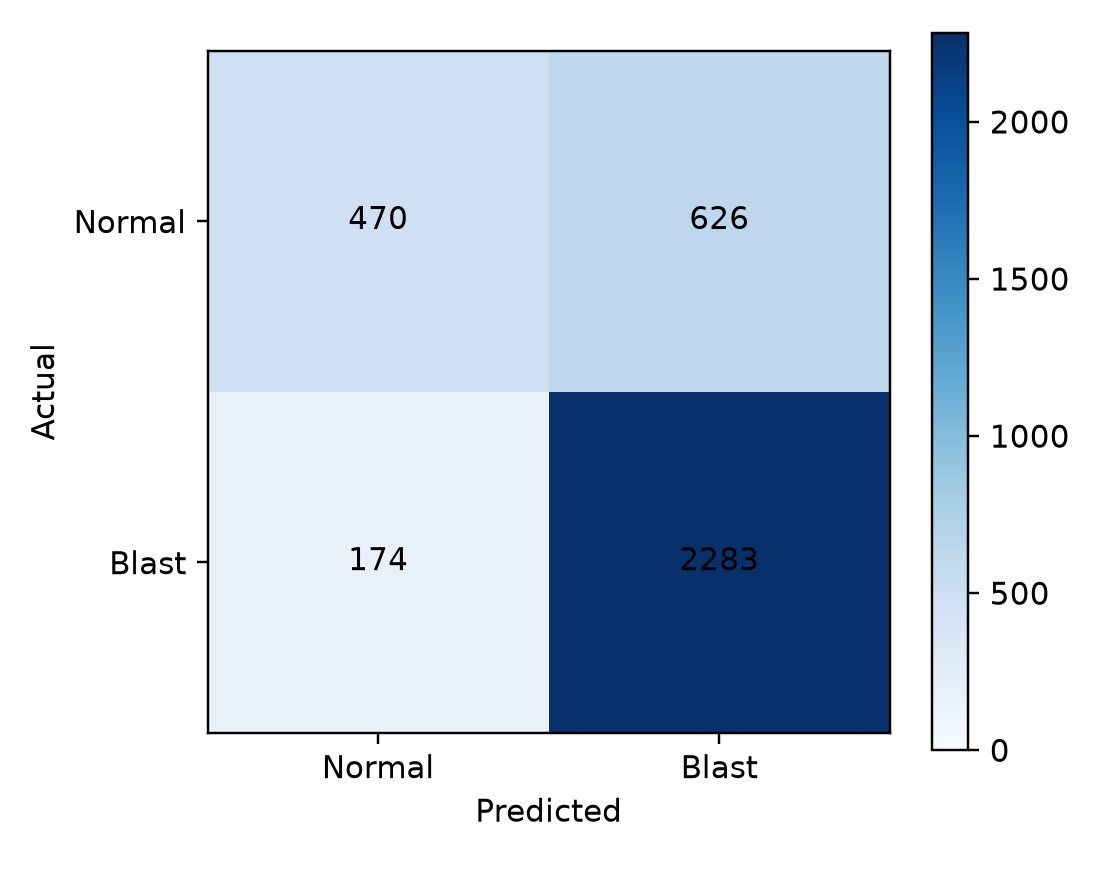

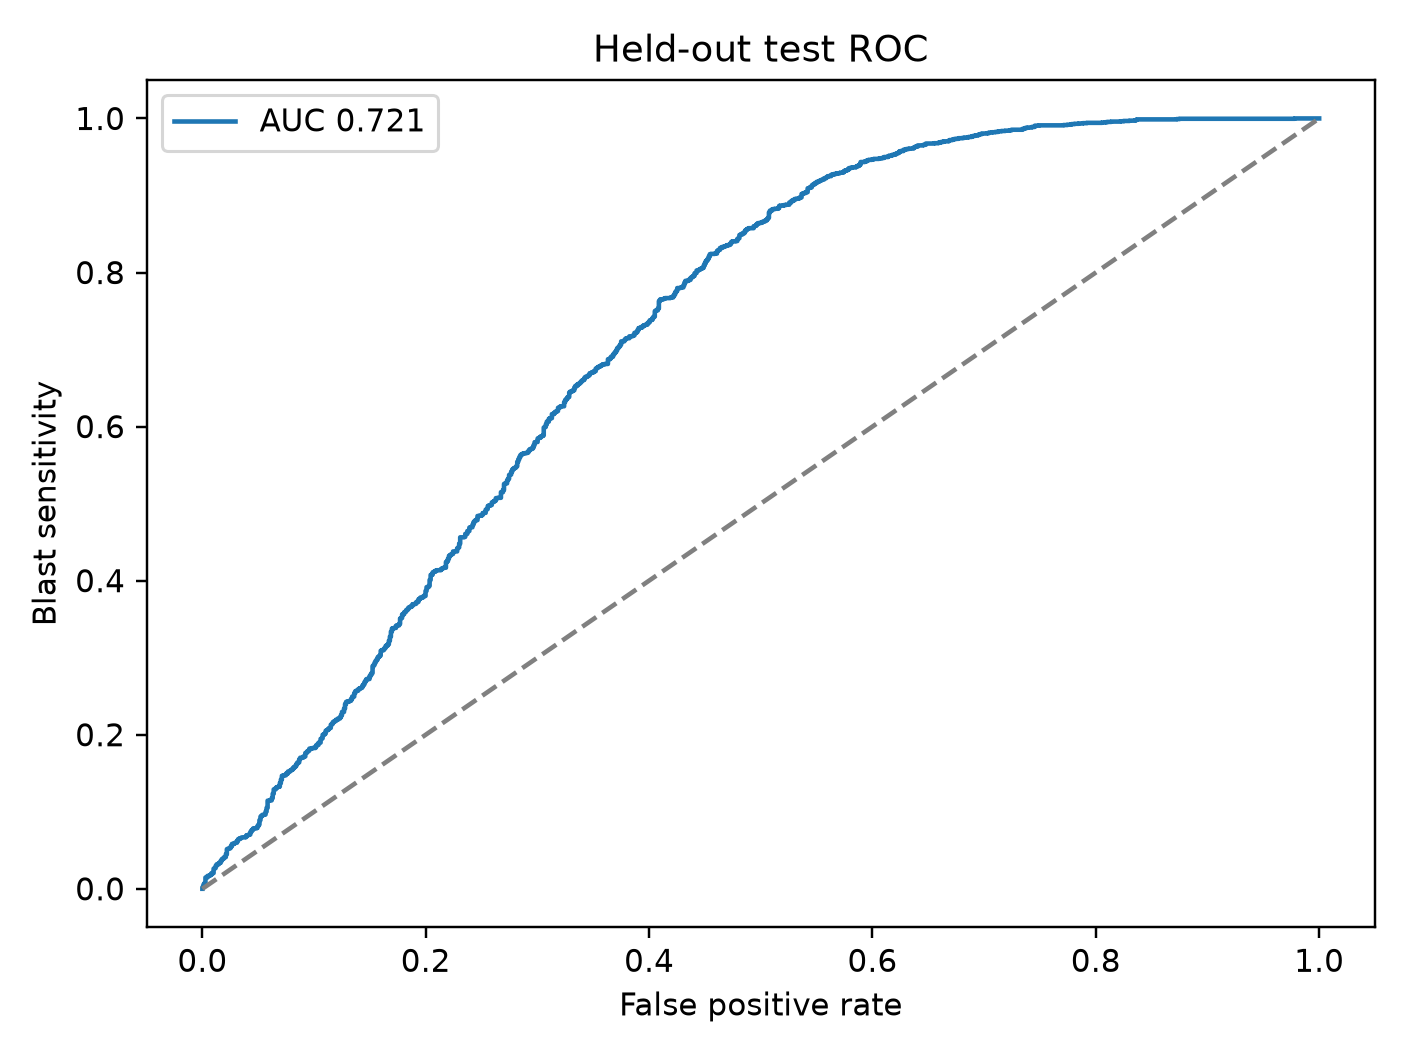

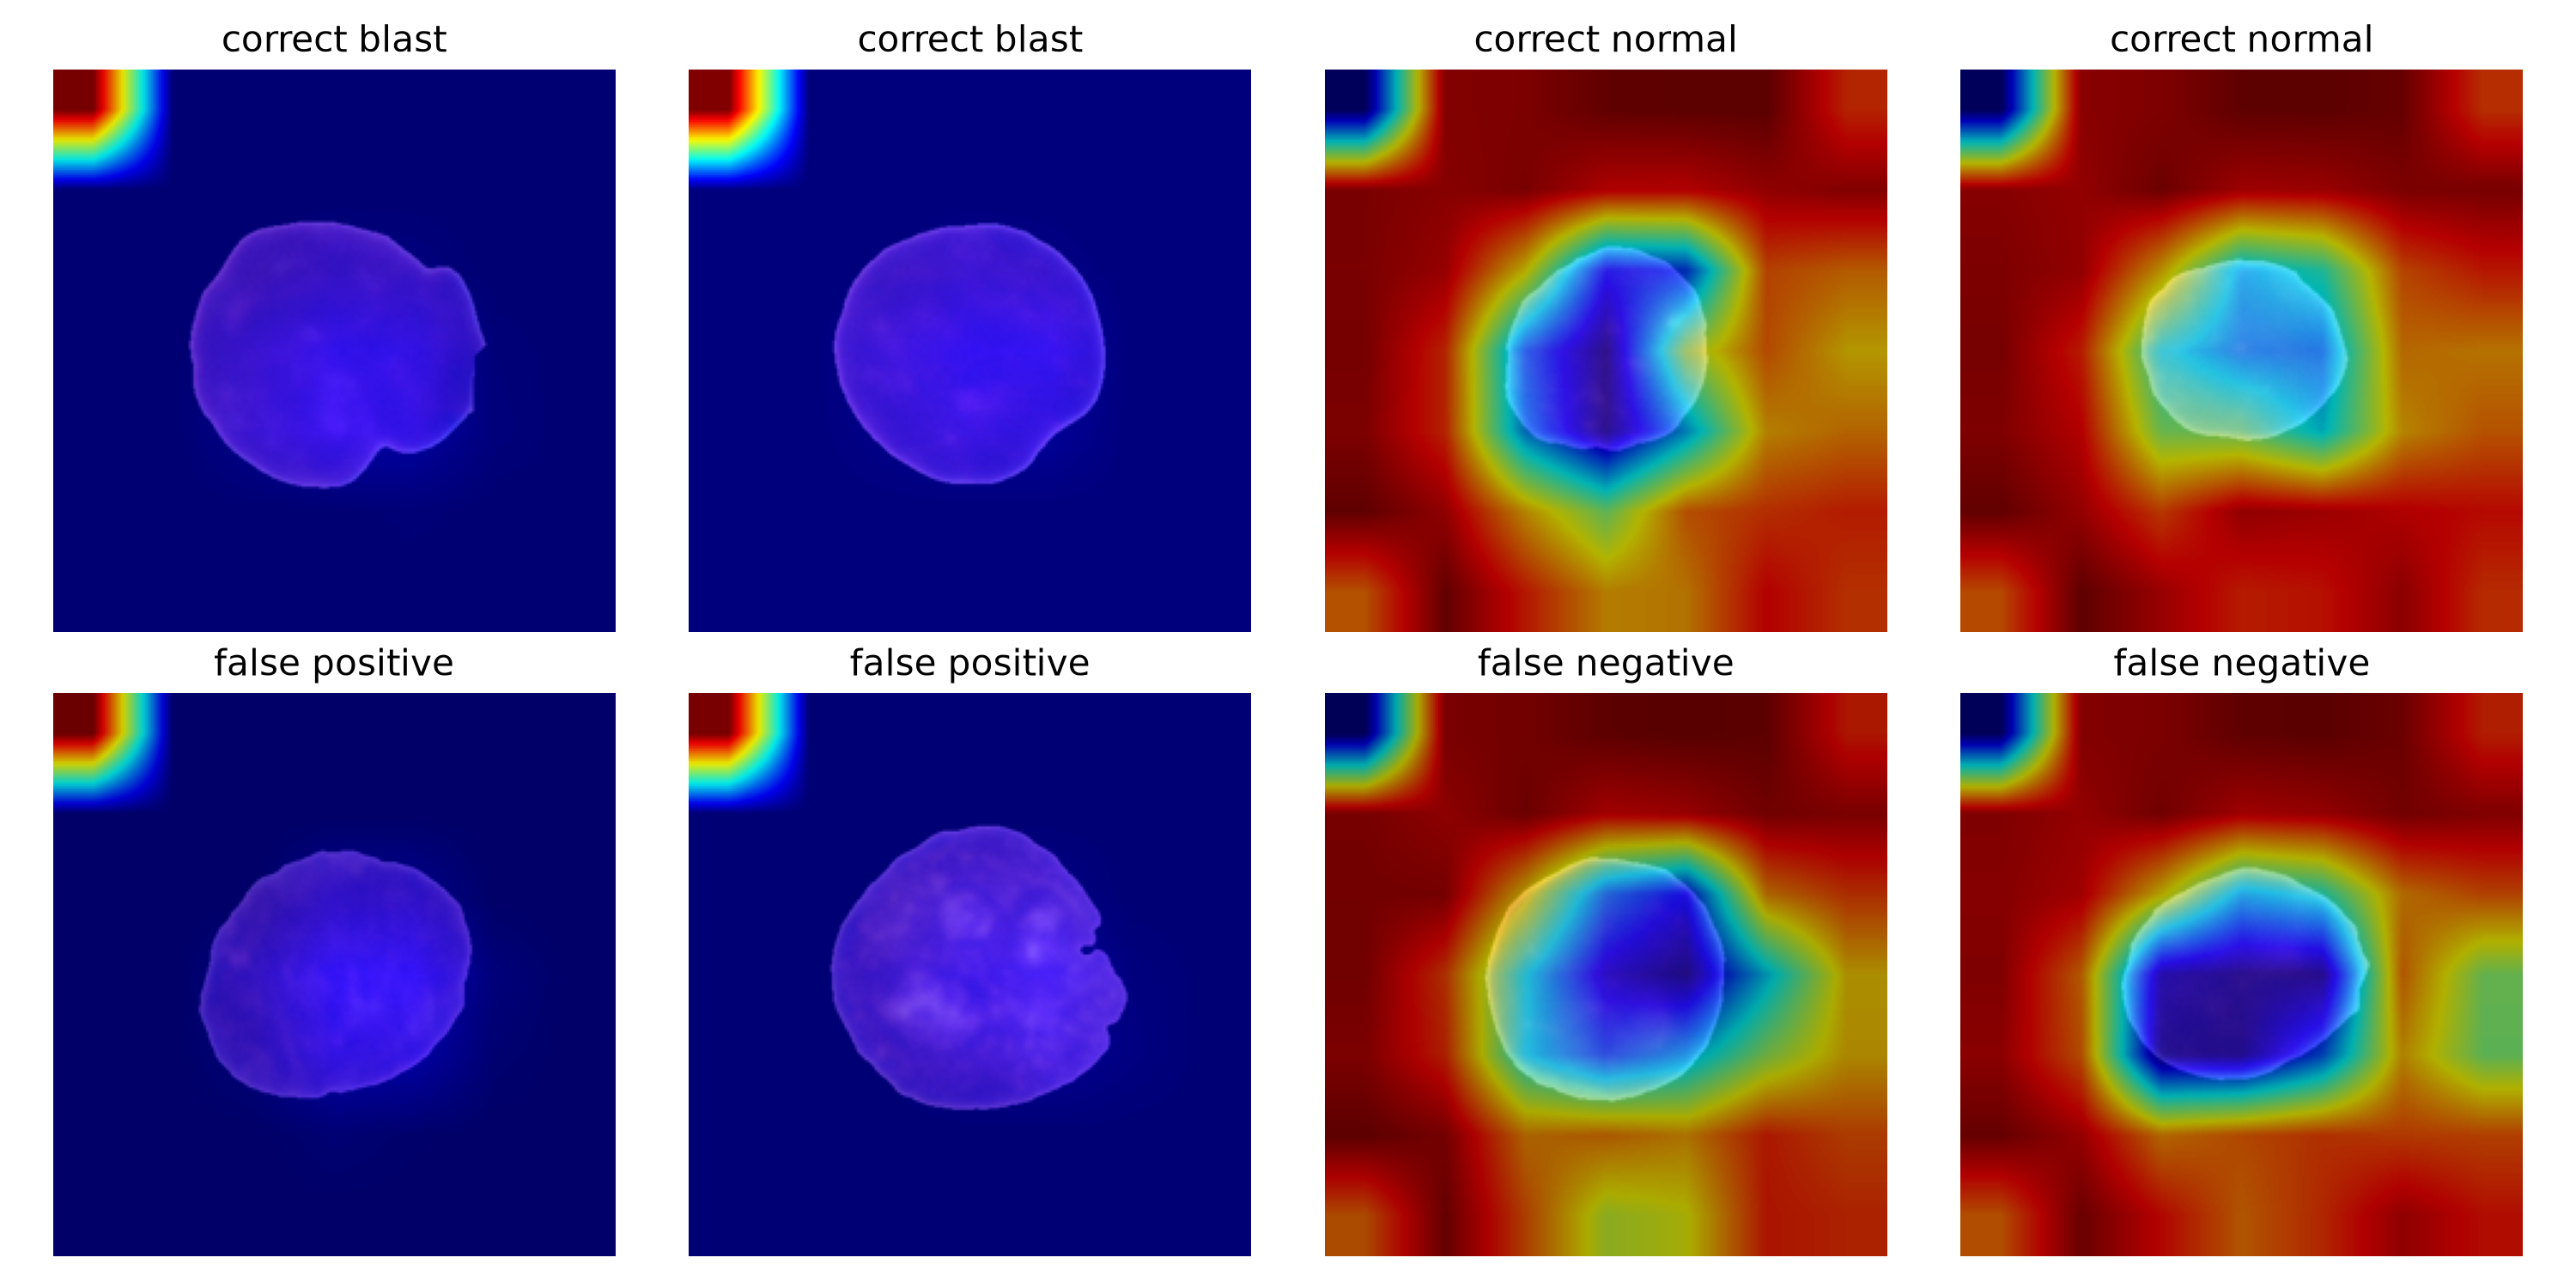

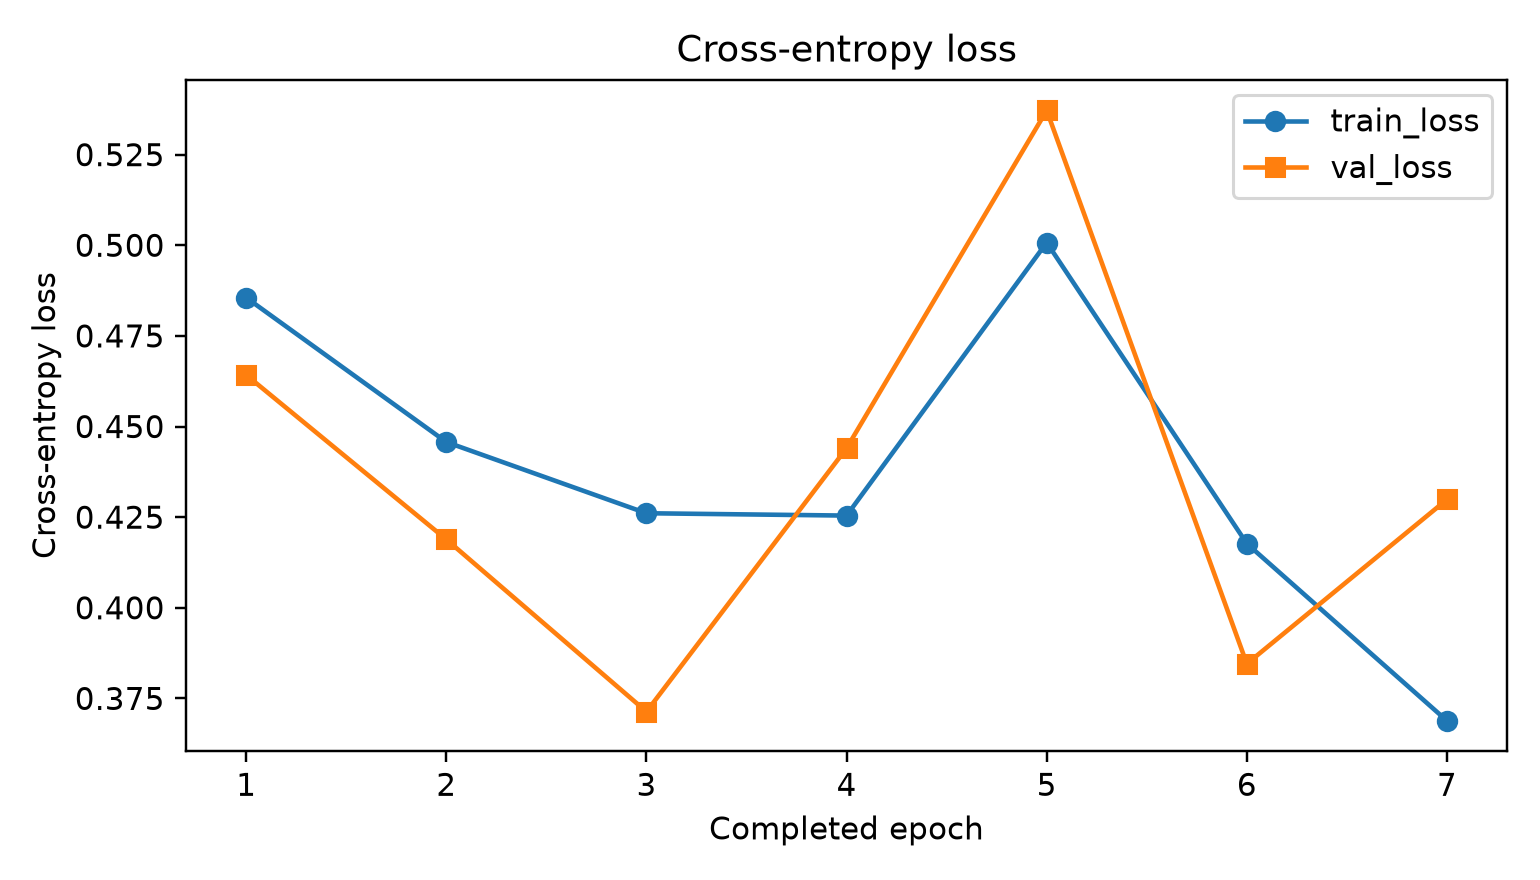

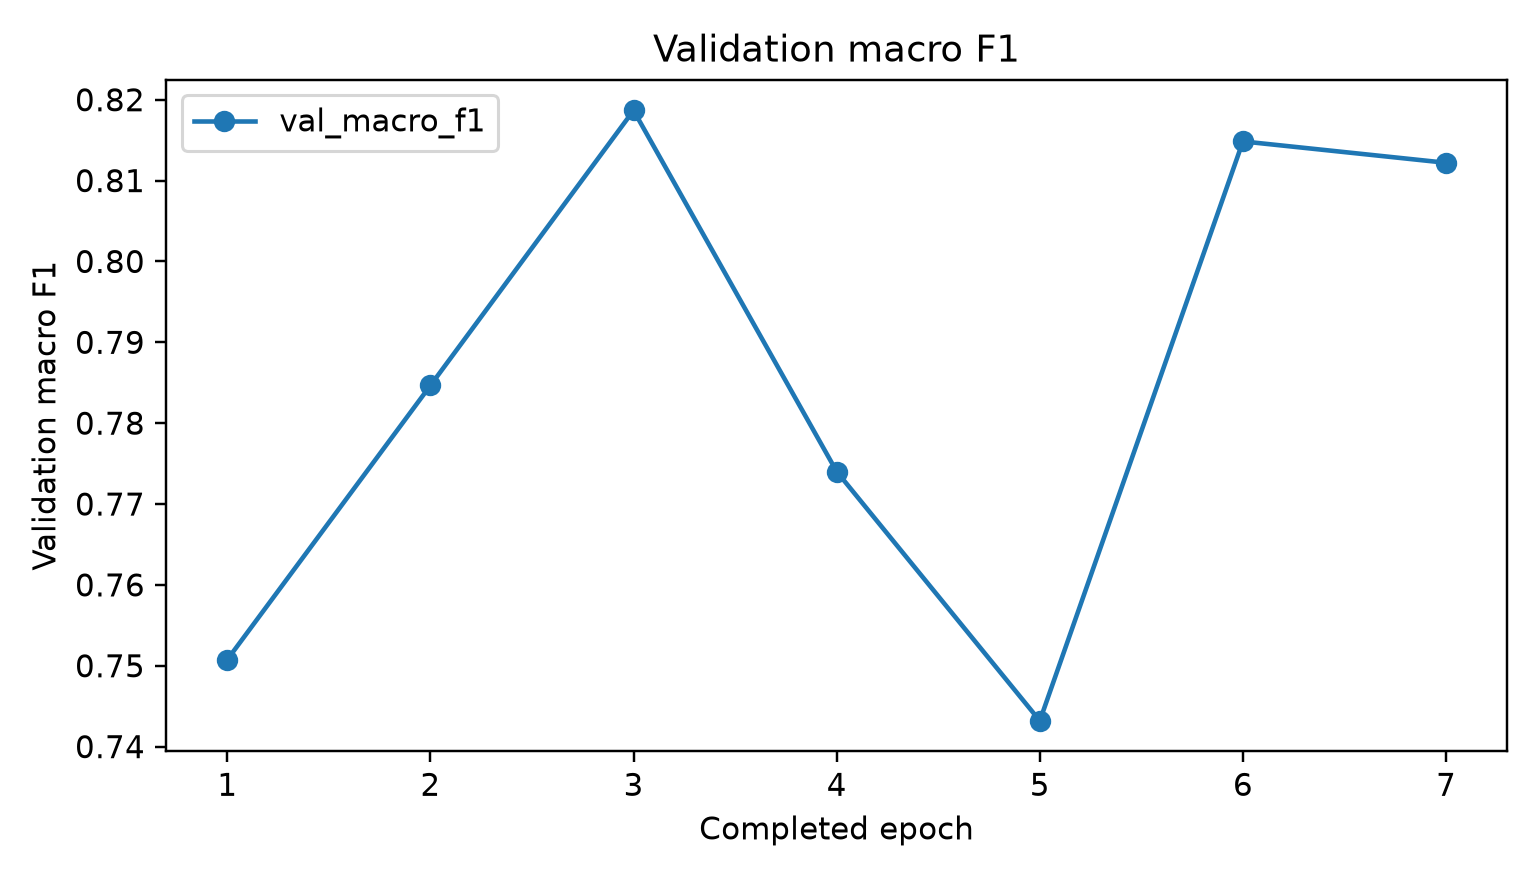

Cell-level C-NMC classification on subject-disjoint source folds is not clinical validation. Grad-CAM is explanatory visualization, not proof of a specific medical feature. YOLO localization and EfficientNet classification scores are separate; no end-to-end accuracy has been measured.


In [3]:
from IPython.display import Image as DisplayImage, display
for file in (out / "paper_results" / "confusion_matrix.png", out / "paper_results" / "roc_curve.png",
             out / "gradcam" / "gradcam_publication_grid.png"):
    if file.is_file(): display(DisplayImage(filename=str(file)))
try:
    from src.classifier_config import latest_classifier_run
    latest = latest_classifier_run(cfg)
    for name in ("loss_curve.png", "f1_curve.png"):
        if (latest / name).is_file(): display(DisplayImage(filename=str(latest / name)))
except FileNotFoundError:
    print("Training curves: Not available")
print(report["limitations"])

## 4. Confirm export

No missing metric is replaced by an invented number.

In [4]:
for name in ("classifier_experiment_summary.md", "classifier_results_table.csv", "classifier_methodology.md", "classifier_limitations.md"):
    assert (out / "paper_results" / name).is_file()
print("PASS — paper documents exported to", out / "paper_results")

PASS — paper documents exported to D:\CellCancer\leukemia-yolo\outputs\classifier\paper_results


## Next

Review the generated report and figures. Integrating YOLO crops into a combined pipeline is a later stage.